# CNN Animals10 데이터셋
- 웹에서 수집된 총 10가지 서로 다른 동물 카테고리의 이미지들로 구성되어 있습니다.
주로 이미지 분류 모델을 처음부터 학습시키거나 전이학습(Transfer Learning)을 실습하는 용도로 활용됩니다

[Animals10 데이터셋](https://www.kaggle.com/datasets/alessiocorrado99/animals10)

In [8]:
import os
import time
import platform
from shutil import rmtree
from dotenv import load_dotenv

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as image
import seaborn as sns

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, TensorDataset, random_split

import torchvision
import torchvision.transforms as transforms
import torchvision.models as models
from torchvision.datasets import ImageFolder
from torchvision.utils import make_grid

# 1. 운영체제별 한글 폰트 설정
if platform.system() == 'Windows':
    plt.rc('font', family='Malgun Gothic')
elif platform.system() == 'Darwin':  # Mac OS
    plt.rc('font', family='AppleGothic')
else:  # Linux (Colab 등)
    plt.rc('font', family='NanumBarunGothic')

# 2. 마이너스 기호(-) 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False

# 오류 발생시
sklearn.set_config(display="text")

In [10]:
print(os.getcwd())                       # .env가 이 폴더에 있어야 함
print(load_dotenv())                     # True면 .env를 읽은 것
token = os.getenv("KAGGLE_API_TOKEN")
print(token[:5] if token else "토큰 없음")

/Users/kdt_0900_cjs/ml/workspace
True
KGAT_


In [11]:
from kaggle.api.kaggle_api_extended import KaggleApi

api = KaggleApi()
api.authenticate()

output_dir = r"/Users/kdt_0900_cjs/ml/resource/dataset"
os.makedirs(output_dir, exist_ok=True)
api.dataset_download_files(r"alessiocorrado99/animals10", path=output_dir, unzip=True)

print("다운로드 완료")

Dataset URL: https://www.kaggle.com/datasets/alessiocorrado99/animals10
다운로드 완료


## ImageFolder
 - 라벨링, 폴더를 가져와서 각 폴더의 레이블로 묶어주는 모듈

In [103]:
base_path = output_dir
folder_name = "raw-img"
file_path = os.path.join(base_path, folder_name)

In [14]:
file_path

'/Users/kdt_0900_cjs/ml/resource/dataset/raw-img'

In [17]:
base_dataset = ImageFolder(root = file_path, transform=None)

In [18]:
print(len(base_dataset))

26179


In [104]:
total_size = len(base_dataset)
train_size = int(total_size * 0.8)
test_size = total_size - train_size

In [21]:
print(train_size, test_size)

20943 5236


In [105]:
train_subset, test_subset = random_split(base_dataset, [train_size, test_size])

In [106]:
train_transfrom = transforms.Compose([
    transforms.Resize((64, 64)), # 크기를 변경
    transforms.Grayscale(1), #흑백
    # transforms.RandomInvert(1) #흑백반전
    transforms.ToTensor(),
    transforms.Normalize(0.5, 0.5)   
])

test_transfrom = transforms.Compose([
    transforms.Resize((64, 64)), # 크기를 변경
    transforms.Grayscale(1), #흑백
    # transforms.RandomInvert(1) #흑백반전
    transforms.ToTensor(),
    transforms.Normalize(0.5, 0.5)
])

In [107]:
class DatasetWrapper(Dataset):
    def __init__(self, dataset, transform=None):
        self.dataset = dataset
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        x, y = self.dataset[idx]
        if self.transform:
            x = self.transform(x)

        return x, y

In [108]:
train_dataset = DatasetWrapper(train_subset, transform = train_transfrom)
test_dataset = DatasetWrapper(test_subset, transform = test_transfrom)

In [47]:
print(len(train_dataset), len(test_dataset))

20943 5236


In [109]:
class_dict = dict(enumerate(base_dataset.classes))
print(class_dict)

{0: 'cane', 1: 'cavallo', 2: 'elefante', 3: 'farfalla', 4: 'gallina', 5: 'gatto', 6: 'mucca', 7: 'pecora', 8: 'ragno', 9: 'scoiattolo'}


In [110]:
train_dataloader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_dataloader = DataLoader(test_dataset, batch_size=64, shuffle=False)

In [111]:
imgs, labels = next(iter(train_dataloader))

In [64]:
print("이미지:", imgs.shape)
print("라벨:", labels.shape)

이미지: torch.Size([64, 1, 64, 64])
라벨: torch.Size([64])


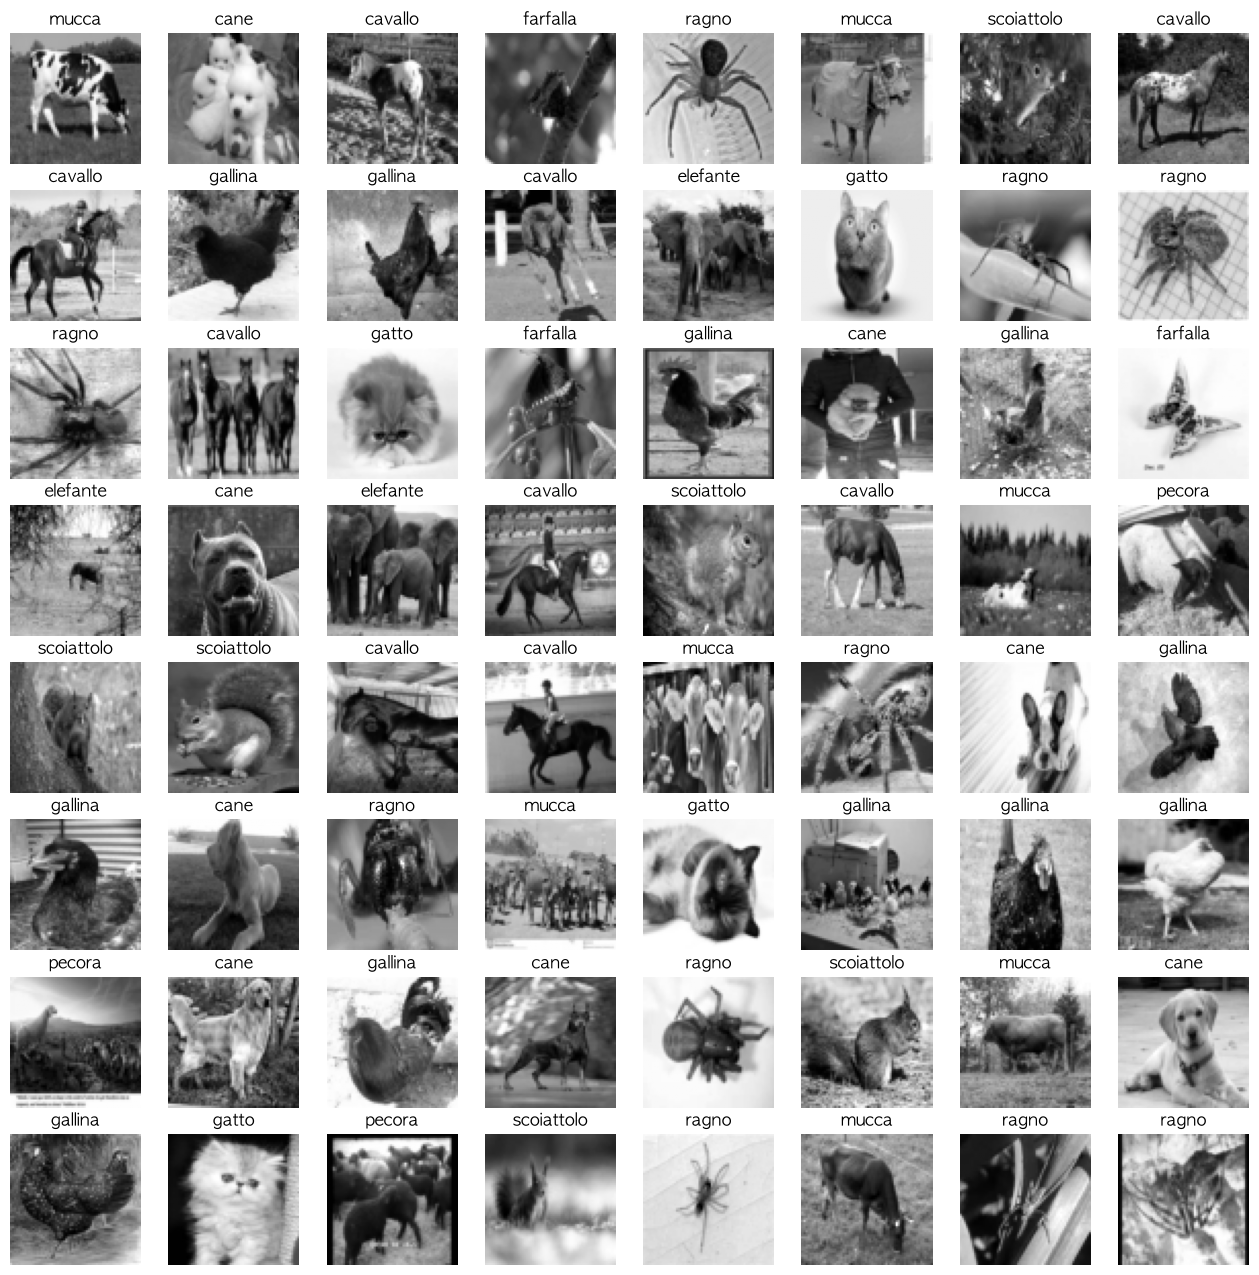

In [112]:
fig, axes = plt.subplots(8, 8, figsize=(16, 16))

for ax, img, label in zip(axes.flatten(), imgs, labels):
    ax.imshow(img.reshape(64, 64), cmap="gray")
    ax.set_title(class_dict[label.item()])
    ax.axis("off")


plt.show()

In [113]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.mps.is_available():
    device = torch.device("mps")
elif torch.xpu.is_available():
    device = torch.device("xpu")
else:
    device = torch.device("cpu")

print(f"현재 선택된 장치: {device}")

현재 선택된 장치: mps


## CNN모델 준비

In [114]:
class ConvNenuralNetwork(nn.Module):
    def __init__(self):
        super(ConvNenuralNetwork, self).__init__()
        self.flatten = nn.Flatten()
        self.classifier = nn.Sequential(
            nn.Conv2d(1, 28, kernel_size=3, padding="same"), # 64 64
            nn.ReLU(), # 활성화 함수
            nn.Conv2d(28, 28, kernel_size=3, padding="same"),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2), # 32 32
            nn.Dropout(0.25), # 과대적합을 없애는 목적
            nn.Conv2d(28, 56, kernel_size=3, padding="same"),
            nn.ReLU(),
            nn.Conv2d(56, 56, kernel_size=3, padding="same"),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2), ## 16 16,
            nn.Dropout(0.25)
        )

        self.linear = nn.Linear(56 * 16 * 16, 10)
            
    def forward(self, x):
        x = self.classifier(x)
        x = self.flatten(x)
        x = self.linear(x)
        return x

In [115]:
model = ConvNenuralNetwork().to(device)

In [116]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [117]:
def train_one_epoch(model, dataloader, criterion, optimizer, device, log_step=20):
    model.train()
    total = 0
    running_loss = 0.0
    running_corrects = 0

    for i, (imgs, labels) in enumerate(dataloader, 1):
        imgs, labels = imgs.to(device), labels.to(device)

        #초기화
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        batch_size = imgs.size(0)
        running_loss += loss.item() * batch_size
        _, preds = outputs.max(1)
        running_corrects += (preds == labels).sum().item()
        total += batch_size

        if log_step and i % log_step == 0:
            batch_acc = (preds == labels).float().mean().item()
            print(f"[Train] batch {i}/{len(dataloader)} | Loss {loss:.4f} | Accuracy : {batch_acc:.2f}")

    return running_loss / total, running_corrects / total

In [118]:
def evaluate(model, dataloader, criterion, device):
    model.eval()
    total = 0
    running_loss = 0.0
    running_corrects = 0

    with torch.no_grad():
        for i, (imgs, labels) in enumerate(dataloader, 1):
            imgs, labels = imgs.to(device), labels.to(device)
    
            # 초기화
            outputs = model(imgs)
            loss = criterion(outputs, labels)
    
            batch_size = imgs.size(0)
            running_loss += loss.item() * batch_size
            _, preds = outputs.max(1)
            running_corrects += (preds == labels).sum().item()
            total += batch_size

    return running_loss / total, running_corrects / total

In [120]:
epochs = 10

for i in range(epochs):
    #학습
    train_loss, train_acc = train_one_epoch(
        model=model,
        dataloader = train_dataloader,
        criterion = criterion,
        optimizer = optimizer,
        device=device
    )

    test_loss, test_acc = evaluate(
        model=model,
        dataloader=test_dataloader,
        criterion=criterion,
        device=device
    )

    print(f"Epoch: {i}/{epochs}")
    print(f"[Train] Loss: {train_loss:.4f} | Accuracy: {train_acc}")
    print(f"[Test] Loss: {test_loss:.4f} | Accuracy: {test_acc}")

[Train] batch 20/328 | Loss 0.5988 | Accuracy : 0.81
[Train] batch 40/328 | Loss 0.5736 | Accuracy : 0.86
[Train] batch 60/328 | Loss 0.6113 | Accuracy : 0.80
[Train] batch 80/328 | Loss 0.5763 | Accuracy : 0.78
[Train] batch 100/328 | Loss 0.7408 | Accuracy : 0.75
[Train] batch 120/328 | Loss 0.5010 | Accuracy : 0.84
[Train] batch 140/328 | Loss 0.5110 | Accuracy : 0.83
[Train] batch 160/328 | Loss 0.4672 | Accuracy : 0.81
[Train] batch 180/328 | Loss 0.7175 | Accuracy : 0.75
[Train] batch 200/328 | Loss 0.8357 | Accuracy : 0.64
[Train] batch 220/328 | Loss 0.7573 | Accuracy : 0.77
[Train] batch 240/328 | Loss 0.4608 | Accuracy : 0.86
[Train] batch 260/328 | Loss 0.6694 | Accuracy : 0.78
[Train] batch 280/328 | Loss 0.7814 | Accuracy : 0.73
[Train] batch 300/328 | Loss 0.6296 | Accuracy : 0.80
[Train] batch 320/328 | Loss 0.6004 | Accuracy : 0.80
Epoch: 0/10
[Train] Loss: 0.6536 | Accuracy: 0.7735758964809244
[Test] Loss: 1.2309 | Accuracy: 0.6201298701298701
[Train] batch 20/328 | Lo

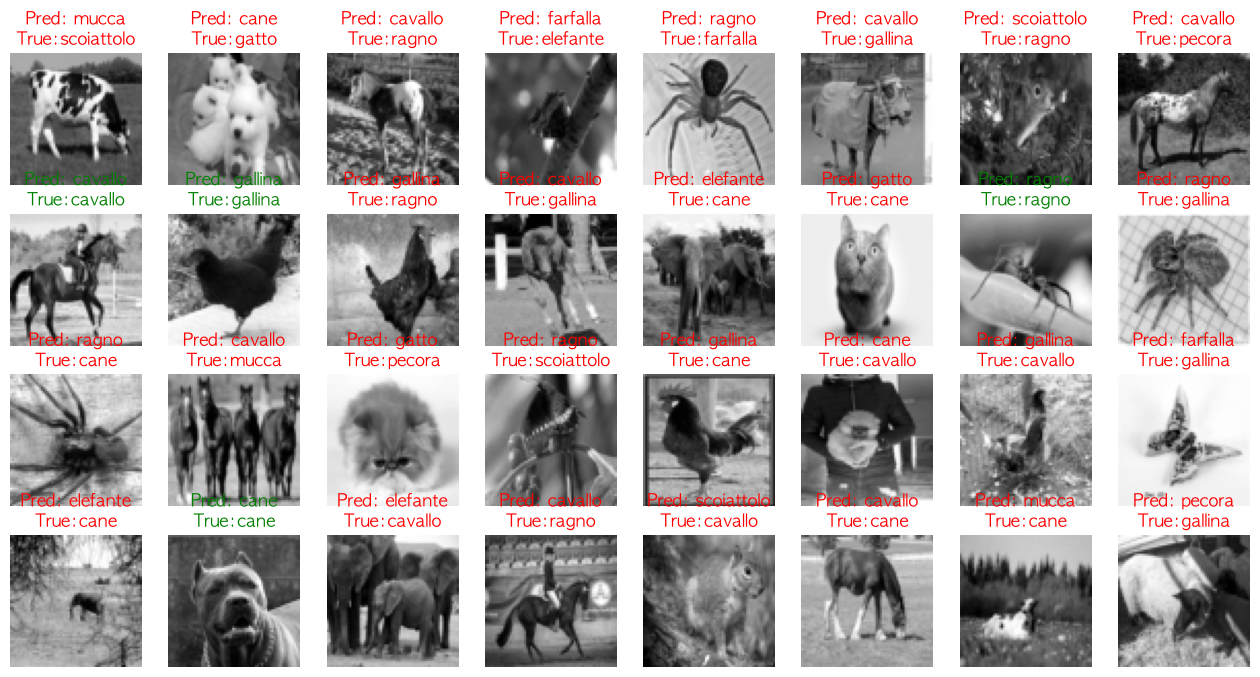

In [122]:
model.eval()

lmgs, labels = next(iter(test_dataloader))
imgs_dev = imgs.to(device)

with torch.no_grad():
    outputs = model(imgs_dev)
    _, preds = outputs.max(1)

img_list_cpu=imgs.cpu()
y_pred_list_cpu = preds.cpu()
y_true_list_cpu = labels.cpu()

fig, axes = plt.subplots(4, 8, figsize=(16, 8))

for ax, img, y_pred, y_true in zip(axes.flatten(), img_list_cpu, y_pred_list_cpu, y_true_list_cpu):
    ax.imshow(img.squeeze(), cmap="gray")

    pred_label = class_dict[y_pred.item()]
    true_label = class_dict[y_true.item()]
    color= "green" if pred_label == true_label else "red"
    ax.axis("off")
    ax.set_title(f"Pred: {pred_label}\nTrue:{true_label}", color=color)

plt.show()

## 사진들고오기

'/Users/kdt_0900_cjs/ml/resource/profile.jpg'

In [125]:
from PIL import Image

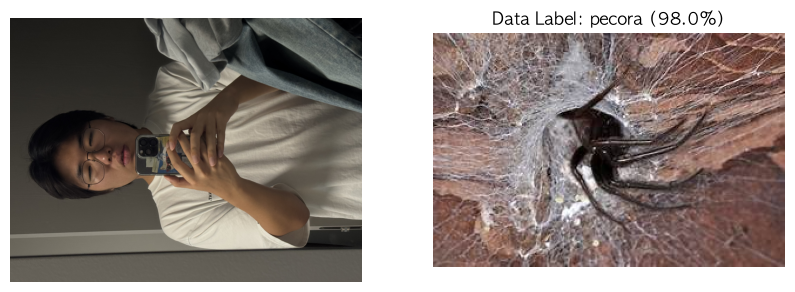

In [136]:
image = Image.open(img_path).convert("RGB")
input_tensor = test_transfrom(image)
input_tensor_dev = input_tensor.unsqueeze(0).to(device)

model.eval()
with torch.no_grad():
    outputs = model(input_tensor_dev)
    probs = F.softmax(outputs, dim=1)[0]

    pred_idx = torch.argmax(probs).item()
    pred_class = class_dict[pred_idx]
    confidence = probs[pred_idx].item() * 100

dataset_sample_img = None

for sample_img, sample_label in base_dataset:
    if sample_label == pred_idx:
        dataset_sample_img = sample_img
        break

fig, axes = plt.subplots(1, 2, figsize=(10,5))

    #내이미지
axes[0].imshow(image)
axes[0].axis("off")

#닮은 이미지
axes[1].imshow(dataset_sample_img)
axes[1].set_title(f"Data Label: {pred_label} ({confidence:.1f}%)")
axes[1].axis("off")

plt.show()